In [1]:
import os
import sys
from IPython.display import Markdown, SVG, display

def find_order_analyzer_parent(start=None):
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, "features")) and os.path.isdir(os.path.join(current, "OCTA_toolbox-master")):
            return os.path.abspath(os.path.join(current, os.pardir))
        if os.path.isdir(os.path.join(current, "order_analyzer")) and os.path.isdir(os.path.join(current, "order_analyzer", "features")):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise RuntimeError(f"Cannot find order_analyzer parent from cwd={os.getcwd()}")
        current = parent

project_parent = find_order_analyzer_parent()
if project_parent not in sys.path:
    sys.path.insert(0, project_parent)

from order_analyzer import Chair, OrderAnalyzer, Table

print("added path:", project_parent)
print("cwd:", os.getcwd())

added path: D:\PROJECTS\understandOtherPackage
cwd: D:\PROJECTS\understandOtherPackage\order_analyzer


In [2]:
LAYOUT_SIZE = (360, 360)
RESOLUTION = 20

def T(id, edges=(), depth=60, **kwargs):
    edge_depth = {edge: depth for edge in edges}
    return Table(
        id=id,
        size=(64, 44),
        affordance={"usable_edges": tuple(edges), "edge_depth": edge_depth},
        **kwargs,
    )

def C(id, **kwargs):
    return Chair(id=id, size=30, affordance={"usable_edges": ()}, **kwargs)

ideal = [
    [T("t00", edges=("right",)), C("c01"), T("t02", edges=("left",))],
    [C("c10"), T("t11", edges=("top", "bottom")), C("c12")],
    [T("t20", edges=("right",)), C("c21"), T("t22", edges=("left",))],
]

actual = [
    [T("t00", edges=("right",), depth=80), T("blocker_01", edges=()), T("t02", edges=("left",), depth=80)],
    [C("c10"), T("t11", edges=("top", "bottom")), C("c12")],
    [T("t20", edges=("right",)), C("c21"), T("t22", edges=("left",))],
]

### OCTA native rendering: ideal 3x3

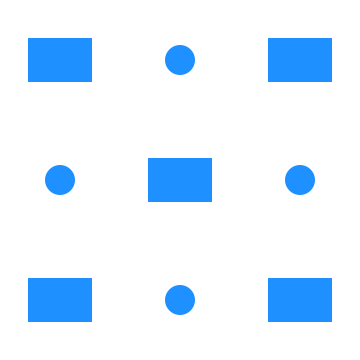

### OCTA native rendering: actual 3x3

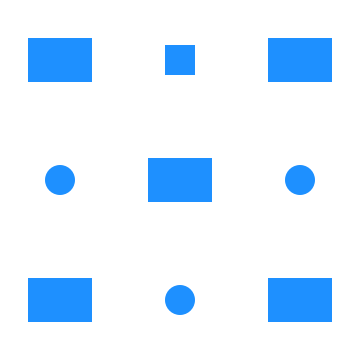

In [3]:
display(Markdown("### OCTA native rendering: ideal 3x3"))
ideal_view = OrderAnalyzer(actual_matrix=ideal, ideal_matrix=ideal, layout_size=LAYOUT_SIZE, fit_to_layout=True)
ideal_view._prepare()
ideal_view._stim.Show()

display(Markdown("### OCTA native rendering: actual 3x3"))
actual_view = OrderAnalyzer(actual_matrix=actual, ideal_matrix=ideal, layout_size=LAYOUT_SIZE, fit_to_layout=True)
actual_view._prepare()
actual_view._stim.Show()

In [4]:
report = OrderAnalyzer(
    actual_matrix=actual,
    ideal_matrix=ideal,
    layout_size=LAYOUT_SIZE,
    fit_to_layout=True,
).report(
    features=("shapes", "orientations"),
    include_affordance=True,
    affordance_options={"width": LAYOUT_SIZE[0], "height": LAYOUT_SIZE[1], "resolution": RESOLUTION},
)

print("order:", report["order"])
print("affordance score:", report["affordance"]["score"])
print("aisle score:", report["aisle"]["score"])
print("affordance violations:", report["affordance"]["violations"])
print("aisle bottlenecks:", report["aisle"]["bottlenecks"])

order: 0.8889
affordance score: 0.8889
aisle score: 1.0
affordance violations: [{'type': 'affordance_coverage_low', 'severity': 'soft', 'object_ids': ['t00'], 'required': 1.0, 'actual': 0.5, 'blocked_edges': ['right'], 'suggestion_hint': 'increase_clearance'}, {'type': 'affordance_coverage_low', 'severity': 'soft', 'object_ids': ['t02'], 'required': 1.0, 'actual': 0.5, 'blocked_edges': ['left'], 'suggestion_hint': 'increase_clearance'}]
aisle bottlenecks: []


### Spatial debug maps from the same 3x3 report

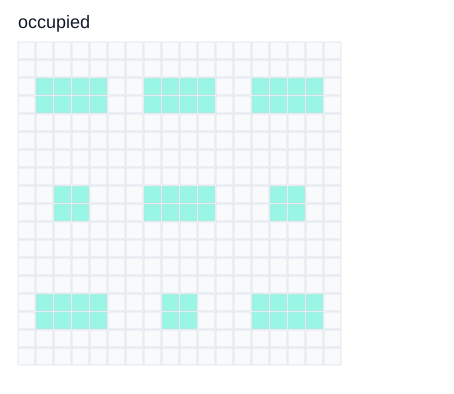

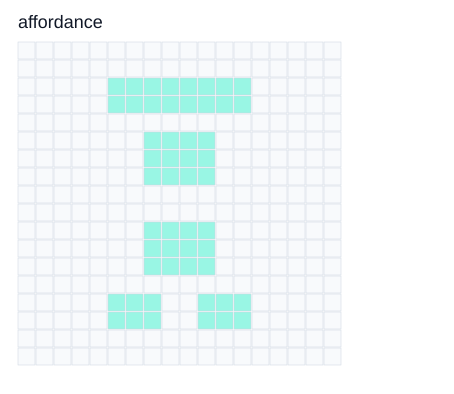

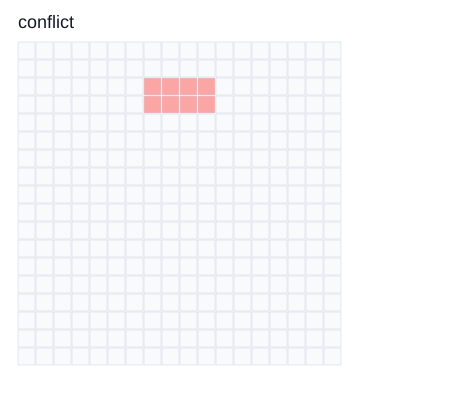

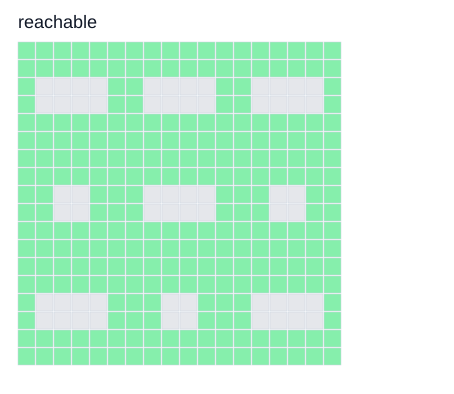

In [5]:
def matrix_to_svg(matrix, title, palette=None, cell=18):
    palette = palette or {0: "#f8fafc", 1: "#99f6e4", 2: "#2dd4bf", 3: "#0f766e"}
    rows = len(matrix)
    cols = len(matrix[0]) if rows else 0
    width = cols * cell + 130
    height = rows * cell + 70
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="18" y="28" font-size="18" font-family="Arial, sans-serif" fill="#111827">{title}</text>',
    ]
    for r, row in enumerate(matrix):
        for c, value in enumerate(row):
            color = palette.get(value, "#0f172a")
            x = 18 + c * cell
            y = 42 + r * cell
            parts.append(f'<rect x="{x}" y="{y}" width="{cell - 1}" height="{cell - 1}" fill="{color}" stroke="#cbd5e1" stroke-width="0.5"/>')
    parts.append('</svg>')
    return SVG(''.join(parts))

display(Markdown("### Spatial debug maps from the same 3x3 report"))
display(matrix_to_svg(report["affordance"]["debug"]["occupied"], "occupied"))
display(matrix_to_svg(report["affordance"]["debug"]["affordance"], "affordance"))
display(matrix_to_svg(report["affordance"]["debug"]["conflict"], "conflict", palette={0: "#f8fafc", 1: "#fca5a5", 2: "#dc2626"}))
display(matrix_to_svg(report["aisle"]["debug"]["reachable"], "reachable", palette={0: "#e5e7eb", 1: "#86efac"}))